# Results so far: Steps 2-4, plus a first look at the standard filter (Step 5 preview)

Research plan: `../../Research_Plan.md`. This notebook only reads what the scripts in `../scripts/` wrote (results, splits, recipes, logs), so it is a view on the results, not where the work happens. Re-run it after re-running the scripts.

Data in this run: MIT-BIH Arrhythmia, NSTDB (noise), QTDB. PTB-XL is not downloaded yet, so the rhythm task is missing from everything below. Same for LUDB, BUT QDB, SimEMG and the wearable data.

Step 1 (novelty check / reading) is still ongoing in parallel and not covered here.

Two cells (marked) need `../data_out/`, which the Step 4 script writes locally and git ignores. Everything else runs from the committed files.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# works from the repo root or from research/notebooks
root = Path.cwd()
while not (root / "Research_Plan.md").exists() and root != root.parent:
    root = root.parent
RESEARCH = root / "research"
assert (RESEARCH / "scripts" / "common.py").exists(), f"can't find research/ from {Path.cwd()}"
sys.path.insert(0, str(RESEARCH / "scripts"))
from common import make_noisy, power, snr_db, DEFAULT_SNRS, NOISE_TYPES

levels = [s for s in DEFAULT_SNRS if s != "clean"]   # 24, 12, 6, 0, -6
types = NOISE_TYPES + ["mix"]
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100
RESEARCH

PosixPath('/home/user/ecg_denoise/research')

## Step 2: data inventory

What is on disk and which labels exist. Output of `step2_inventory.py`.

In [2]:
inv = pd.read_csv(RESEARCH / "results" / "data_inventory.csv")
keep = ["wfdb_records", "sampling_rates_hz", "n_channels", "total_hours",
        "duration_sec_min/median/max", "total_labelled_beats"]
inv[inv["item"].isin(keep)].pivot(index="item", columns="dataset", values="value").reindex(keep)

dataset,mitdb,nstdb,qtdb
item,,,
wfdb_records,48,15,105
sampling_rates_hz,{360: 48},{360: 15},{250: 105}
n_channels,{2: 48},{2: 15},{2: 105}
total_hours,24.07,7.52,26.25
duration_sec_min/median/max,1805.6 / 1805.6 / 1805.6,1805.6 / 1805.6 / 1805.6,900.0 / 900.0 / 900.0
total_labelled_beats,109494,NaN,NaN


In [3]:
# which annotation files exist -> which tasks are possible
inv[inv["item"].str.startswith("records_with_")][["dataset", "item", "value"]]

,dataset,item,value
9,mitdb,records_with_.atr (reference beat labels),48
21,nstdb,records_with_.atr (reference beat labels),12
34,qtdb,records_with_.atr (reference beat labels),82
35,qtdb,records_with_.q1c (manual wave boundaries (car...,105
36,qtdb,records_with_.q2c (manual wave boundaries (car...,11
37,qtdb,records_with_.pu (automatic wave boundaries),105
38,qtdb,records_with_.pu0 (automatic wave boundaries ch0),105
39,qtdb,records_with_.pu1 (automatic wave boundaries ch1),105
40,qtdb,records_with_.man (manual beat annotations),105


MIT-BIH has beat labels (`.atr`) for all 48 records, so the heartbeat detection task is fine.
QTDB has the cardiologist wave boundaries (`.q1c`) on all 105 records, so wave timing is fine.
NSTDB has the three noise recordings bw / ma / em. The 118eXX / 119eXX records in NSTDB are MIT-BIH with noise already mixed in at fixed levels; we don't use them, we mix our own.

Rhythm classification needs PTB-XL. Not yet.

## Step 3: splits

Patient-wise splits, and the NSTDB noise cut in time so test noise is never seen in training. `step3_splits.py` also runs the leakage check.

In [4]:
print((RESEARCH / "splits" / "split_check.txt").read_text(encoding="utf-8"))

seed=0
PASS: 133 patient groups, each in exactly one split (checked across MIT-BIH and QTDB together).
PASS: noise 'bw' train/val/test ranges do not overlap
PASS: noise 'em' train/val/test ranges do not overlap
PASS: noise 'ma' train/val/test ranges do not overlap
mitdb: {'test': '21 records / 21 patients', 'train': '19 records / 18 patients', 'val': '4 records / 4 patients'}
qtdb: {'test': '27 records / 27 patients', 'train': '57 records / 57 patients', 'val': '19 records / 19 patients'}



In [5]:
mit = pd.read_csv(RESEARCH / "splits" / "mitdb.csv", dtype={"record": str})
qt = pd.read_csv(RESEARCH / "splits" / "qtdb.csv", dtype={"record": str})
pd.concat({
    "mitdb records": mit["split"].value_counts(),
    "qtdb records": qt["split"].value_counts(),
    "qtdb with q1c": qt[qt["has_q1c"]]["split"].value_counts(),
}, axis=1).fillna(0).astype(int)

,mitdb records,qtdb records,qtdb with q1c
split,,,
test,21,27,27
train,19,57,57
excluded_paced,4,2,2
val,4,19,19


In [6]:
# MIT-BIH: DS1/DS2 of de Chazal et al. 202 moved to train because it is the same patient as 201.
for s, g in mit.groupby("split"):
    print(f"{s:15s}", " ".join(g["record"]))

excluded_paced  102 104 107 217
test            100 103 105 111 113 117 121 123 200 210 212 213 214 219 221 222 228 231 232 233 234
train           101 106 108 109 112 115 116 118 119 124 201 202 205 207 209 215 220 223 230
val             114 122 203 208


In [7]:
noise = pd.read_csv(RESEARCH / "splits" / "nstdb_noise.csv")
noise

,noise_record,split,start_sample,end_sample,fs,minutes
0,bw,train,0,390000,360,18.06
1,bw,val,390000,520000,360,6.02
2,bw,test,520000,650000,360,6.02
3,ma,train,0,390000,360,18.06
4,ma,val,390000,520000,360,6.02
5,ma,test,520000,650000,360,6.02
6,em,train,0,390000,360,18.06
7,em,val,390000,520000,360,6.02
8,em,test,520000,650000,360,6.02


Only about 6 min of test noise per type (20% of 30 min). Enough for the test windows since each window draws a random 10 s segment, but segments repeat across windows, so the windows are not independent draws of noise. Worth remembering when we look at per-window spread later.

## Step 4: noisy test signals

10 s windows, channel 0, noise added at 24 / 12 / 6 / 0 / -6 dB for bw, ma, em and a mix. The same noise segment is used at every level for a given window so the levels are paired. Only the recipe is saved (which segment, start sample, scale); `make_noisy()` rebuilds the signal exactly from it.

SNR = 10 log10(P_clean / P_noise), both with the mean removed.

In [8]:
pd.concat([pd.read_csv(RESEARCH / "results" / f"E0_noise_build_{s}.csv") for s in ["test", "val"]])

,dataset,split,fs,windows,records,noisy_signals,max_snr_error_db
0,mitdb,test,360,3780,21,75600,7.105427e-15
1,qtdb,test,250,2422,27,48440,7.105427e-15
0,mitdb,val,360,720,4,14400,7.105427e-15
1,qtdb,val,250,1698,19,33960,7.105427e-15


In [9]:
rec = pd.read_csv(RESEARCH / "recipes" / "mitdb_test.csv.gz")
print(rec.shape)
rec.head(8)

(79380, 13)


,dataset,split,window_id,record,start_sample,fs,noise_type,snr_db,start_bw,start_ma,start_em,scale,achieved_snr_db
0,mitdb,test,0,100,0,360,none,clean,-1,-1,-1,0.000000,inf
1,mitdb,test,0,100,0,360,bw,24,107518,-1,-1,0.027107,24.0
2,mitdb,test,0,100,0,360,bw,12,107518,-1,-1,0.107915,12.0
3,mitdb,test,0,100,0,360,bw,6,107518,-1,-1,0.215319,6.0
4,mitdb,test,0,100,0,360,bw,0,107518,-1,-1,0.429618,0.0
5,mitdb,test,0,100,0,360,bw,-6,107518,-1,-1,0.857201,-6.0
6,mitdb,test,0,100,0,360,ma,24,-1,80511,-1,0.050254,24.0
7,mitdb,test,0,100,0,360,ma,12,-1,80511,-1,0.200063,12.0


In [10]:
# sanity: achieved SNR == target SNR (should be exact up to float error)
noisy_rows = rec[rec.noise_type != "none"].assign(snr_db=lambda d: d.snr_db.astype(int))
err = (noisy_rows["achieved_snr_db"] - noisy_rows["snr_db"]).abs()
print("max |achieved - target| =", err.max(), "dB")
noisy_rows.groupby(["noise_type", "snr_db"]).size().unstack()[levels]

max |achieved - target| = 4.440892098500626e-15 dB


snr_db,24,12,6,0,-6
noise_type,,,,,
bw,3780,3780,3780,3780,3780
em,3780,3780,3780,3780,3780
ma,3780,3780,3780,3780,3780
mix,3780,3780,3780,3780,3780


Rebuild one window from the recipe and look at it at every level. **Needs `data_out/`.**

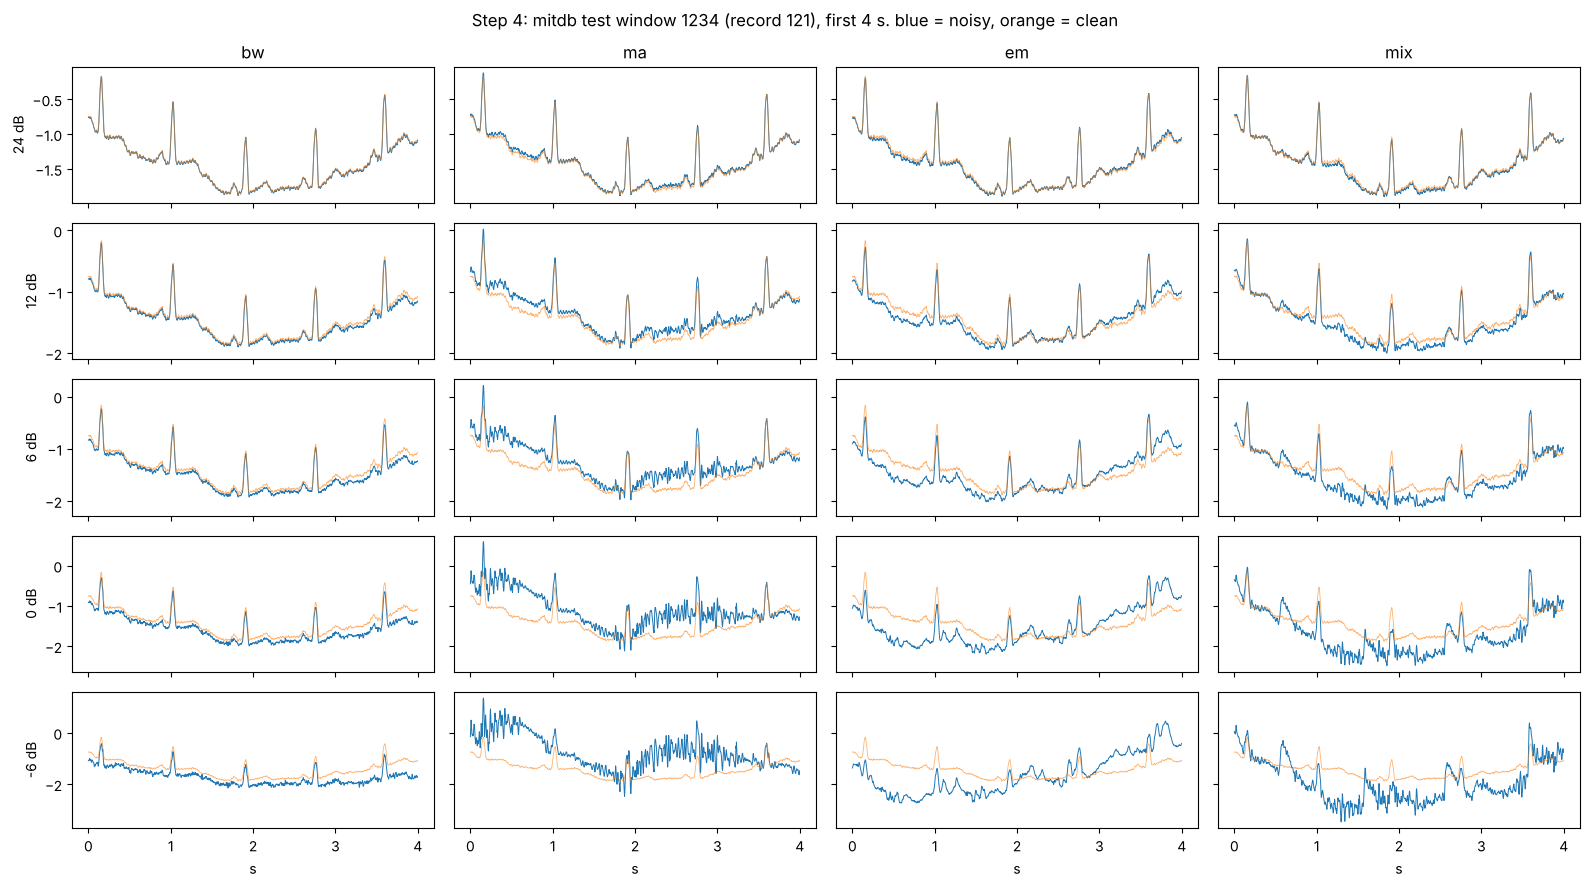

In [11]:
clean = np.load(RESEARCH / "data_out" / "mitdb_test_clean.npz")
X, fs = clean["X"].astype(float), int(clean["fs"])
bank = dict(np.load(RESEARCH / "data_out" / f"noise_bank_test_{fs}.npz"))
t = np.arange(X.shape[1]) / fs

wid = min(1234, len(X) - 1)
x = X[wid]
rows = rec[rec.window_id == wid]
show = slice(0, 4 * fs)

fig, axes = plt.subplots(len(levels), 4, figsize=(16, 9), sharex=True, sharey="row")
for j, ntype in enumerate(types):
    for i, s in enumerate(levels):
        r = rows[(rows.noise_type == ntype) & (rows.snr_db.astype(str) == str(s))].iloc[0]
        y = make_noisy(x, bank, r.to_dict())
        ax = axes[i, j]
        ax.plot(t[show], y[show], lw=0.7)
        ax.plot(t[show], x[show], lw=0.6, alpha=0.6)
        if i == 0: ax.set_title(ntype)
        if j == 0: ax.set_ylabel(f"{s} dB")
for ax in axes[-1]: ax.set_xlabel("s")
fig.suptitle(f"Step 4: mitdb test window {wid} (record {rows.record.iloc[0]}), first 4 s. blue = noisy, orange = clean")
fig.tight_layout();

Looks as expected. bw is slow drift, ma is the high-frequency fuzz, em has the big excursions. At -6 dB the QRS is still visible under bw but basically gone under em.

The Step 4 figures for 5 random windows per dataset and noise type are in `../figures/noise_examples/`.

## Step 5 preview: does the simplest cleaner help?

Not the full Step 5. Just cleaner #2 from the plan (Butterworth 0.5-40 Hz band-pass, 4th order, plus 60 Hz notch, both zero-phase) applied to 300 random test windows per dataset. The point was to check the Step 4 data is usable and get a first feel for P1/P3. Script: `step5_preview_filter.py`. Logged as `E1-preview-filter-mitdb` / `-qtdb` in `../logs/experiment_log.md`.

The 300 windows come from 21 (mitdb) / 27 (qtdb) records, roughly 10-17 windows per record, so they are clustered, not 300 independent samples.

Output SNR = 10 log10(P_clean / P_error) with error = filter output minus the clean reference, mean removed.

In [12]:
e1 = {ds: pd.read_csv(RESEARCH / "results" / f"E1_preview_filter_{ds}.csv") for ds in ["mitdb", "qtdb"]}
for ds, df in e1.items():
    print(ds, len(df[df.noise_type == "none"]), "windows from", df.record.nunique(), "records")
e1["mitdb"].head()

mitdb 300 windows from 21 records
qtdb 300 windows from 27 records


,window_id,record,noise_type,snr_db,snr_in_db,snr_out_db,rmse_noisy,rmse_cleaned,rel_distortion,snr_gain_db
0,2838,222,none,clean,inf,4.516841,0.000000,0.242068,0.594508,-inf
1,2838,222,bw,24,2.400000e+01,4.517830,0.007675,0.242089,0.594441,-19.482170
2,2838,222,bw,12,1.200000e+01,4.492864,0.030553,0.242221,0.596152,-7.507136
3,2838,222,bw,6,6.000000e+00,4.396358,0.060962,0.242558,0.602812,-1.603642
4,2838,222,bw,0,-2.951426e-08,4.008626,0.121635,0.243775,0.630331,4.008626


In [13]:
def gain_table(df):
    d = df[df.noise_type != "none"].assign(snr_db=lambda d: d.snr_db.astype(int))
    d["gain"] = d["snr_out_db"] - d["snr_in_db"]
    return d.pivot_table(index="snr_db", columns="noise_type", values="gain", aggfunc="median") \
            .reindex(levels)[types].round(1)

for ds, df in e1.items():
    print(f"--- {ds}: median SNR gain (dB) after filter ---")
    print(gain_table(df), "\n")

--- mitdb: median SNR gain (dB) after filter ---
noise_type    bw    ma    em   mix
snr_db                            
 24        -12.5 -12.6 -12.7 -12.6
 12         -0.6  -1.3  -2.5  -1.7
 6           5.3   2.7   0.1   2.0
 0          10.4   5.2   1.2   3.7
-6          14.3   6.4   1.9   4.7 

--- qtdb: median SNR gain (dB) after filter ---
noise_type    bw    ma    em   mix
snr_db                            
 24        -10.7 -10.7 -10.9 -10.7
 12          1.2   0.2  -1.3  -0.2
 6           6.9   3.8   0.6   2.9
 0          11.6   5.7   1.4   4.4
-6          15.3   6.6   1.7   5.0 



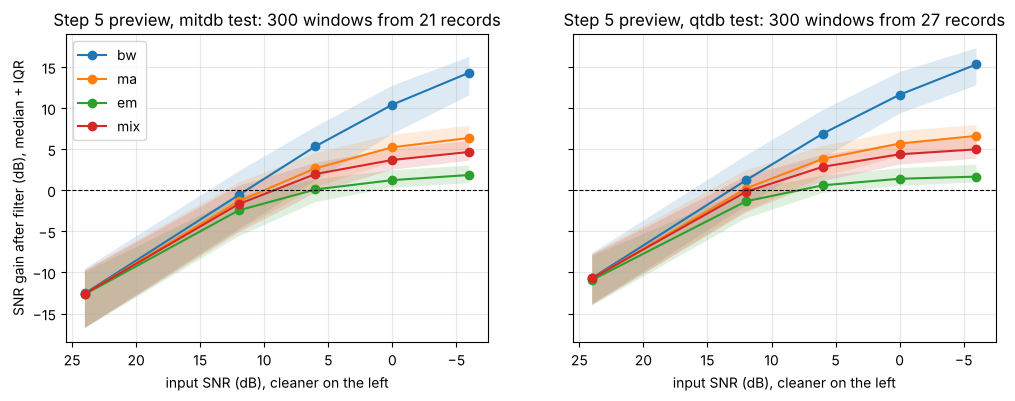

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (ds, df) in zip(axes, e1.items()):
    d = df[df.noise_type != "none"].assign(snr_db=lambda d: d.snr_db.astype(int))
    d["gain"] = d["snr_out_db"] - d["snr_in_db"]
    for ntype in types:
        g = d[d.noise_type == ntype].groupby("snr_db")["gain"]
        med, lo, hi = g.median(), g.quantile(0.25), g.quantile(0.75)
        ax.plot(med.index, med.values, marker="o", label=ntype)
        ax.fill_between(med.index, lo.values, hi.values, alpha=0.15)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.invert_xaxis()
    ax.set_xlabel("input SNR (dB), cleaner on the left")
    ax.set_title(f"Step 5 preview, {ds} test: {d.window_id.nunique()} windows from {d.record.nunique()} records")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("SNR gain after filter (dB), median + IQR")
axes[0].legend();

Both datasets go the same way: the filter clearly helps at 6 dB and below, and the output SNR is clearly lower than the input at 24 dB. The crossover is around 12 dB but not identical: on mitdb the median gain is already slightly negative at 12 dB for all four noise types; on qtdb bw and ma are still marginally positive there (+1.2 / +0.2 dB, with 42% / 50% of windows worse), so for those two it is between 12 and 24 dB. em crosses earliest on both. bw is the easy noise (almost all of it is below 0.5 Hz), em the hard one (electrode motion, overlaps the QRS band).

The gain at 24 dB is the same for all four noise types, about -12.5 dB on mitdb and -10.7 on qtdb. That is suspicious: if it were about the noise, the types would differ. It is not about the noise, see below.

mitdb: clean input -> output SNR vs reference: median 11.5 dB (per-record medians range 4.3 to 17.7); relative RMS change median 0.27, 98% of windows changed by more than 10%
qtdb: clean input -> output SNR vs reference: median 13.4 dB (per-record medians range 3.5 to 19.9); relative RMS change median 0.21, 94% of windows changed by more than 10%


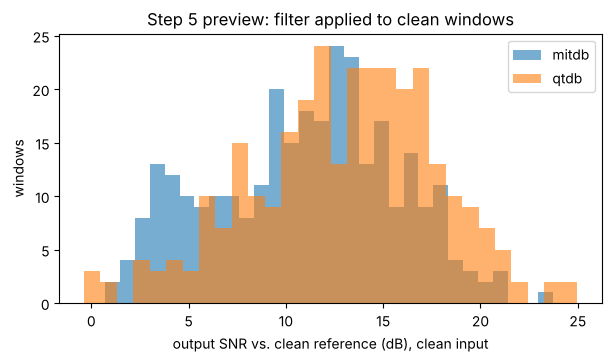

In [15]:
# what does the filter do to an already-clean window?
for ds, df in e1.items():
    c = df[df.noise_type == "none"]
    per_rec = c.groupby("record")["snr_out_db"].median()
    print(f"{ds}: clean input -> output SNR vs reference: median {c.snr_out_db.median():.1f} dB "
          f"(per-record medians range {per_rec.min():.1f} to {per_rec.max():.1f}); "
          f"relative RMS change median {c.rel_distortion.median():.2f}, "
          f"{(c.rel_distortion > 0.1).mean()*100:.0f}% of windows changed by more than 10%")

fig, ax = plt.subplots(figsize=(7, 3.5))
for ds, df in e1.items():
    ax.hist(df[df.noise_type == "none"]["snr_out_db"], bins=30, alpha=0.6, label=ds)
ax.set_xlabel("output SNR vs. clean reference (dB), clean input"); ax.set_ylabel("windows")
ax.set_title("Step 5 preview: filter applied to clean windows"); ax.legend();

### The high-SNR "loss" is mostly the reference, not the noise

The filter is linear, so for a noisy input x + n the error splits exactly into two parts:

    output - x = (H x - x) + H n

The first term is what the filter does to the clean reference itself (removing anything below 0.5 Hz or above 40 Hz, including the record's own baseline wander). The second is the residual noise. The clean-input numbers above say the first term alone caps the output SNR at about 11.5 dB (mitdb) / 13.4 dB (qtdb). So whenever the input SNR is above that ceiling, the measured "loss" is dominated by the reference term and says nothing about how the filter handles the noise.

Check by computing both terms per window and level. **Needs `data_out/`.**

In [16]:
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, welch

def standard_filter(x, fs):   # same as in step5_preview_filter.py
    sos = butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
    b, a = iirnotch(60, Q=30, fs=fs)
    return filtfilt(b, a, sosfiltfilt(sos, x))

wids = sorted(e1["mitdb"].window_id.unique())
out = []
for wid in wids:
    x = X[wid]
    ref_term = power(standard_filter(x, fs) - x)
    for r in rec[(rec.window_id == wid) & (rec.noise_type != "none")].itertuples():
        n = make_noisy(x, bank, r._asdict()) - x
        out.append({"noise_type": r.noise_type, "snr_db": int(r.snr_db),
                    "ratio_ref_over_noise": ref_term / power(standard_filter(n, fs))})
dec = pd.DataFrame(out)
print("median P(Hx - x) / P(Hn), mitdb test, 300 windows. >1 means the reference term dominates the error.")
dec.pivot_table(index="snr_db", columns="noise_type", values="ratio_ref_over_noise", aggfunc="median") \
   .reindex(levels)[types].round(2)

median P(Hx - x) / P(Hn), mitdb test, 300 windows. >1 means the reference term dominates the error.


noise_type,bw,ma,em,mix
snr_db,,,,
24,1357.93,99.65,31.73,55.90
12,85.68,6.29,2.00,3.53
6,21.52,1.58,0.50,0.89
0,5.41,0.40,0.13,0.22
-6,1.36,0.10,0.03,0.06


At 24 dB the reference term is 30 to 1000+ times the residual noise, and at 12 dB it is still above 1 for every type. For ma, em and mix the residual noise only takes over at 6 dB and below (ma: 0 dB and below), so only there does the SNR gain measure the filter's noise handling. For bw the reference term dominates at every level, because the filter removes bw almost completely: the bw "gain" is simply input SNR going to the ceiling, which is why the bw curve is the straightest. The "crossover" above is just where the input SNR meets the clean-input ceiling.

Consequence: with this metric and this reference, nothing can be said about whether the filter hurts at high SNR. That is a metric problem, not a result about P3.

What is in the removed part (H x - x) of the clean windows? Spectral split over all 300 clean windows, plus the worst single window as an example:

In [17]:
clean_wids = sorted(e1["mitdb"][e1["mitdb"].noise_type == "none"].window_id.unique())
frac = []
for wid in clean_wids:
    x = X[wid]
    f, P = welch(x - standard_filter(x, fs), fs, nperseg=fs * 4)
    tot = P.sum()
    frac.append({"below_0.5Hz": P[f < 0.5].sum() / tot, "in_band_0.5-40Hz": P[(f >= 0.5) & (f <= 40)].sum() / tot,
                 "above_40Hz": P[f > 40].sum() / tot})
frac = pd.DataFrame(frac)
print("share of the removed power, mitdb clean windows (n=300):")
frac.describe().loc[["25%", "50%", "75%", "max"]].round(2)

share of the removed power, mitdb clean windows (n=300):


,below_0.5Hz,in_band_0.5-40Hz,above_40Hz
25%,0.46,0.21,0.02
50%,0.58,0.29,0.07
75%,0.70,0.40,0.16
max,0.90,0.83,0.75


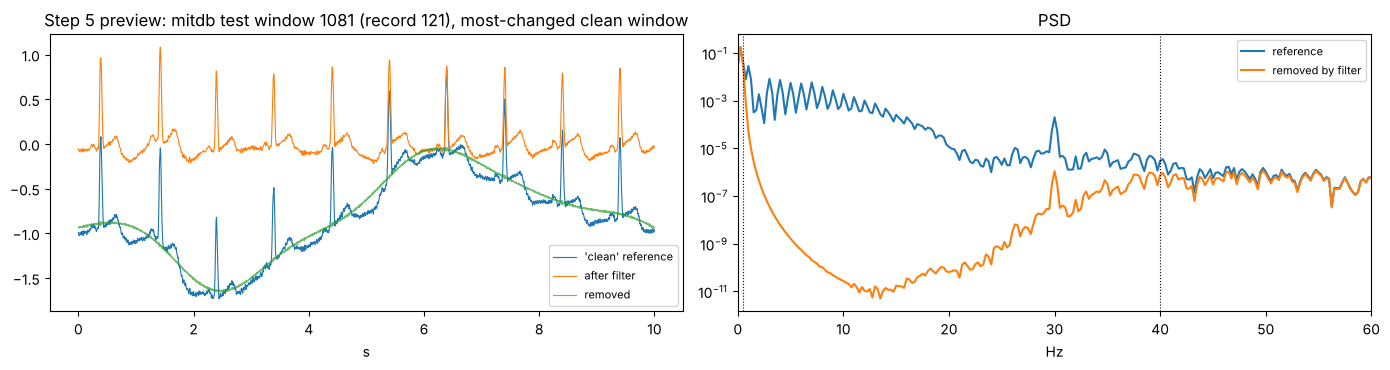

In [18]:
c = e1["mitdb"][e1["mitdb"].noise_type == "none"]
wid = int(c.sort_values("snr_out_db").iloc[0].window_id)
x = X[wid]; y = standard_filter(x, fs)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(t, x, lw=0.8, label="'clean' reference")
axes[0].plot(t, y, lw=0.8, label="after filter")
axes[0].plot(t, x - y, lw=0.8, alpha=0.7, label="removed")
axes[0].set_title(f"Step 5 preview: mitdb test window {wid} (record {c[c.window_id==wid].record.iloc[0]}), most-changed clean window")
axes[0].set_xlabel("s"); axes[0].legend(fontsize=8)

f, Pxx = welch(x - x.mean(), fs, nperseg=fs * 4)
f2, Prem = welch(x - y, fs, nperseg=fs * 4)
axes[1].semilogy(f, Pxx, label="reference"); axes[1].semilogy(f2, Prem, label="removed by filter")
axes[1].axvline(0.5, color="k", ls=":", lw=0.8); axes[1].axvline(40, color="k", ls=":", lw=0.8)
axes[1].set_xlim(0, 60); axes[1].set_xlabel("Hz"); axes[1].set_title("PSD"); axes[1].legend(fontsize=8)
fig.tight_layout();

Across the 300 clean windows about 58% of the removed power is below 0.5 Hz (the reference's own baseline wander), about 7% above 40 Hz, and roughly 29% is in band. So the "distortion on clean input" is mostly the filter taking out wander that is in the reference, but a quarter to a third of it is in-band attenuation, which is real distortion of the ECG. The worst window (record 121 above) is almost entirely wander.

One more thing that inflates the clean-input change: the filter is applied per 10 s window with the default `filtfilt` padding (27 samples), and a 0.5 Hz high-pass needs seconds to settle. Error power in the first and last second vs the middle:

In [19]:
edge = []
for wid in clean_wids:
    d = standard_filter(X[wid], fs) - X[wid]
    e = (d - d.mean()) ** 2          # mean removed, same convention as the SNR
    edge.append(np.r_[e[:fs], e[-fs:]].mean() / e[fs:-fs].mean())
edge = pd.Series(edge)
print(f"mitdb clean windows: edge / middle error power, median {edge.median():.2f}, 75th pct {edge.quantile(.75):.2f}")

mitdb clean windows: edge / middle error power, median 2.52, 75th pct 4.55


So the first and last second carry about 2.5x the error of the middle (4.5x at the upper quartile). That is a start-up transient from filtering short windows, not something the filter does to ECG, and it inflates both the clean-input change and the high-SNR loss. Fix for Step 5 proper: filter the whole record before windowing (or pad by several seconds).

Also: 11 of the 27 QTDB test records are `sele*` (European ST-T, 50 Hz mains), and the notch is at 60 Hz. Needs a per-record mains frequency in Step 5 proper.

What this means for the plan:
- E1 needs an in-band metric (high-pass both reference and output the same way before computing SNR) or a cleaner reference, before P3 can be tested with this filter. The clean-input ceiling must be reported alongside any SNR gain.
- Filter whole records, not windows. Per-record notch frequency.
- Aggregate per record first; 300 windows from 21 records is not 300 samples, and per-record clean-input SNR ranges from about 4 to 18 dB on mitdb.
- This is also the argument for the task-level outcomes (beat detection F1, QT error) over SNR. SNR against an imperfect reference is misleading in exactly the regime P3 cares about.

## Where this leaves us

Status per step is in `../STATUS.md`. Short version: Steps 2-4 done for mitdb / qtdb, Step 5 is a preview with the filter baseline only (DWT and FCN-DAE not started), PTB-XL and the other datasets not downloaded.

Next: finish the reading table (D1), get PTB-XL in and rerun 2-4, then Step 5 properly with the E1 metric fixed as above.